<a href="https://colab.research.google.com/github/Innej3/SupplyNetwork/blob/main/Specialized_Workers_%26_Supply_Networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q mesa

In [ ]:
'''
Leontief Input-Ouput Model
x = Ax + d => x = (I-A)^-1 * d
aij - how much of sectors i's output sector j needs to make one unit


'''

In [ ]:
"""
Leontief (fixed-proportion) production -
q = min(aL, bK) or q = min(K/a, L/b)

L = labor, K = Capital and a,b > 0 are productivity constants
To prodice output q, we need atleast
L >= q/a and K >= q/b
so the efficient input ratio is fixed i.e
L/K = b/a


Isoquants - curve showing all the different combinations of inputs that
produce the same quantity of output.
It shows substitutability between inputs
- smooth, curved isoquants -> inputs can be substituted somewhat easily
- straight line isoquants -> perfect substitution
- L-shaped isoquants -> perfect complements/ fixed protions (leontief), so we cant
sway labor for captial and keep the output the same - extra of one input just sits
there as a bottleneck

"""

In [ ]:
"""
MRTS - marginal rate of technical substitution

FOR STRAIGHT CURVE: can always trade one input for another keeping the output same
a = aL + bK

MRTS(L, K) = MP(L)/MP(K) = a/b = const
elasticity of subsitution (sigma) = inf

L-SHAPES: inputs must be used in fixed propotions, shape is right-angle L, the
corner is the efficient input ratio, no subsitution possible
q = min(aL, bK)

ALong the vertical arm, MRTS = inf (labor is free in excess, but useless)
along the horizontal arm, MRTS=0 (capital is excess, but useless)
At the corner = undefined
elasticity of subsitution (sigma) = 0

Smooth Curve - cobb douglas: downward sloping, convex to origin
q = AL^alpha K^beta, alpha + beta = 1

MRTS = MP(L)/MP(K) = alpha * K / beta * L

MRTS diminises as we move down the curve(more labor less capital) -> labor
becomes relatively less production at the margin
elasticity of subsitution (sigma) = 1

"""

In [ ]:
"""
Wrights law/ learning-by-doing - industrial leraning curve, describe how the cost
pf producing a good falls by a const percentage everything cumulative
produciton doubles

Claim: FOr every cumulative doubling of units produces, the cost (or labor time) per
unit falls by a const percentage, given by
C(x) = C_1 * x^(-b)

b - learning exponent
C_1 - cost of the first unit
x - cumulative production

each doubling of x mulitplies cost by the progress ratio p = 2^(-b)
So LR = 1 - p -> b = -log2(1 - LR)

Wrights original data showed that every time total aircraft production
doubled, the required labor time for a new aircraft fell by about 20%

"""

In [ ]:
import networkx as nx
import mesa
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
"""
Tier 0 - raw extraction, no upstream dependency
Tier 1 - requires specific input from Tier 0
Tier 2 - each requries combination of Tier 1 components
Tier 3 - delivers finished output to the market
"""

In [ ]:
class WorkerNode(mesa.Agent):
  def __init__(self, model, tier, base_capacity=10.0, learning_alpha=0.20, buffer_init=15.0):
    super().__init__(model)
    self.tier = tier
    self.base_capacity = base_capacity
    self.learning_alpha = learning_alpha
    self.buffer_init = buffer_init

    self.cumulative_output = 0.0
    self.current_output = 0.0
    self.is_disrupted = False
    self.input_buffers = {}
    self.finished_inventory = buffer_init

  @property
  def current_capacity(self):
    if self.is_disrupted:
      return 0.0
    return self.base_capacity * ((1.0 + self.cumulative_output / 50.0) ** self.learning_alpha)

  def produce(self):
    cap = self.current_capacity
    if self.tier == 0:
      self.current_output = cap
    else:
      if not self.input_buffers:
        self.current_output = 0.0
      else:
        min_input_available = min(self.input_buffers.values())
        self.current_output = min(cap, min_input_available)

        for u_id in self.input_buffers:
          self.input_buffers[u_id] -= self.current_output
    self.finished_inventory += self.current_output
    self.cumulative_output += self.current_output

  def ship_downstream(self):
    downstream_ids = list(self.model.G.successors(self.unique_id))
    if not downstream_ids or self.finished_inventory <= 0:
      return

    ship_per_node = self.finished_inventory / len(downstream_ids)
    for d_id in downstream_ids:
      d_agent = self.model.agent_map[d_id]
      d_agent.input_buffers[self.unique_id] += ship_per_node
    self.finished_inventory = 0.0

In [ ]:
class SupplyNetworkModel(mesa.Model):
  def __init__(self, tier_sizes=(5,8,6,3), learning_alpha=0.22,
               buffer_init=15.0, shock_window=(30, 50), seed=42):
    super().__init__(seed=seed)
    self.tier_sizes = tier_sizes
    self.shock_window = shock_window
    self.step_count = 0
    self.G = nx.DiGraph()
    self.agent_map = {}

    tiers = []
    for t_idx, size in enumerate(tier_sizes):
      tier_agents = []
      for _ in range(size):
        a = WorkerNode(self, tier=t_idx, base_capacity=10.0,
                       learning_alpha=learning_alpha, buffer_init=buffer_init)
        self.G.add_node(a.unique_id, tier=t_idx)
        self.agent_map[a.unique_id] = a
        tier_agents.append(a)
      tiers.append(tier_agents)

    for t_idx in range(len(tiers) - 1):
      upstream_tier = tiers[t_idx]
      downstream_tier = tiers[t_idx + 1]
      for d_agent in downstream_tier:
        # each downstream worker depends on 2 distinct upstream specialist
        suppliers = self.rng.choice(upstream_tier, size=min(2, len(upstream_tier)), replace=False)
        for s_agent in suppliers:
          self.G.add_edge(s_agent.unique_id, d_agent.unique_id)
          d_agent.input_buffers[s_agent.unique_id] = buffer_init
    self.target_nodes = [tiers[0][0].unique_id, tiers[0][1].unique_id]

    self.datacollector = mesa.DataCollector(
        model_reporters={
            'Tier0_Output': lambda m: m.tier_output(0),
            "Tier1_Output": lambda m: m.tier_output(1),
            "Tier2_Output": lambda m: m.tier_output(2),
            "Final_GDP": lambda m: m.tier_output(3),
        }
    )
  def tier_output(self, tier_idx):
    return sum(a.current_output for a in self.agents if a.tier == tier_idx)

  def step(self):
    in_shock = self.shock_window[0] <= self.step_count <= self.shock_window[1]
    for nid in self.target_nodes:
      self.agent_map[nid].is_disrupted = in_shock

    for agent in self.agents:
      agent.produce()

    for agent in self.agents:
      agent.ship_downstream()

    self.datacollector.collect(self)
    self.step_count += 1

In [ ]:
model = SupplyNetworkModel(buffer_init=15.0, shock_window=(30, 50), seed=42)

/usr/local/lib/python3.13/dist-packages/mesa/mesa_logging.py:112: FutureWarning: The use of the `seed` keyword argument is deprecated, use `rng` instead. No functional changes.
  res = func(*args, **kwargs)


In [ ]:
for _ in range(100):
  model.step()

In [ ]:
df = model.datacollector.get_model_vars_dataframe()

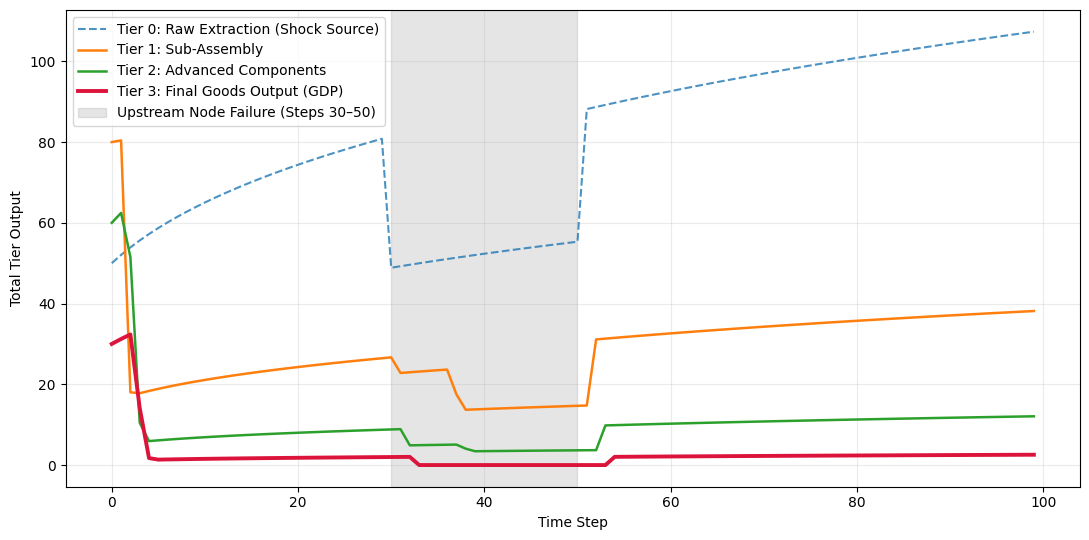

In [ ]:
plt.figure(figsize=(11, 5.5))
plt.plot(df["Tier0_Output"], label="Tier 0: Raw Extraction (Shock Source)", linestyle="--", alpha=0.8)
plt.plot(df["Tier1_Output"], label="Tier 1: Sub-Assembly", linewidth=1.8)
plt.plot(df["Tier2_Output"], label="Tier 2: Advanced Components", linewidth=1.8)
plt.plot(df["Final_GDP"], label="Tier 3: Final Goods Output (GDP)", linewidth=2.8, color="crimson")
plt.axvspan(30, 50, color="gray", alpha=0.2, label="Upstream Node Failure (Steps 30–50)")

plt.xlabel("Time Step")
plt.ylabel("Total Tier Output")
plt.legend(loc="upper left")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [ ]:
class WorkerNode2(mesa.Agent):
  def __init__(self, model, tier, base_capacity=12.0, learning_alpha=0.22, buffer_init=8.0):
    super().__init__(model)
    self.tier = tier
    self.base_capacity = base_capacity
    self.learning_alpha = learning_alpha
    self.target_buffer = buffer_init
    self.max_buffer = buffer_init * 1.5  # Warehouse Cap

    self.cumulative_output = 0.0
    self.current_output = 0.0
    self.is_disrupted = False
    self.retooling_cooldown = 0
    self.input_buffers = {}
    self.starvation_counter = {}
    self.order_posted = {}
    self.finished_inventory = 0.0  # Start with 0 extra finished stock so flow is immediate

  @property
  def current_capacity(self):
    if self.is_disrupted or self.retooling_cooldown > 0:
      return 0.0
    return self.base_capacity * ((1.0 + self.cumulative_output / 60.0) ** self.learning_alpha)

  def post_upstream_orders(self):
    k = len(self.input_buffers)
    if self.tier == 0 or k == 0:
      return

    expected_cap = self.base_capacity * ((1.0 + self.cumulative_output / 60.0) ** self.learning_alpha)
    for u_id, inv in self.input_buffers.items():
      needed_for_prod = expected_cap / k
      buffer_gap = max(0.0, self.target_buffer - inv)
      self.order_posted[u_id] = needed_for_prod + 0.5 * buffer_gap

  def evaluate_rewiring(self):
    if not self.model.enable_rewiring or self.tier == 0:
      return

    starved_suppliers = [
        u_id for u_id, count in self.starvation_counter.items()
        if count >= self.model.patience_threshold and self.input_buffers[u_id] < 1.0
    ]

    if not starved_suppliers:
      return

    current_suppliers = set(self.input_buffers.keys())
    candidates = [
        a for a in self.model.tiers[self.tier - 1]
        if a.unique_id not in current_suppliers and not a.is_disrupted
    ]

    for old_u_id in starved_suppliers:
      if not candidates:
        break

      best_cand = max(
          candidates,
          key=lambda c: c.current_capacity / max(1, self.model.G.out_degree(c.unique_id) + 1)
      )
      candidates.remove(best_cand)

      self.model.G.remove_edge(old_u_id, self.unique_id)
      self.model.G.add_edge(best_cand.unique_id, self.unique_id)

      leftover = self.input_buffers.pop(old_u_id, 0.0)
      self.starvation_counter.pop(old_u_id, None)
      self.order_posted.pop(old_u_id, None)

      self.input_buffers[best_cand.unique_id] = leftover * 0.5
      self.starvation_counter[best_cand.unique_id] = 0
      self.order_posted[best_cand.unique_id] = self.target_buffer

      self.cumulative_output *= (1.0 - self.model.switching_penalty)
      self.retooling_cooldown = 1
      self.model.rewire_events += 1

  def produce(self):
    if self.retooling_cooldown > 0:
      self.retooling_cooldown -= 1
      self.current_output = 0.0
      return

    cap = self.current_capacity
    if self.tier == 0:
      self.current_output = cap
    else:
      k = len(self.input_buffers)
      if k == 0:
        self.current_output = 0.0
      else:
        max_producible_by_inputs = min(inv * k for inv in self.input_buffers.values())
        self.current_output = min(cap, max_producible_by_inputs)

        for u_id in self.input_buffers:
          self.input_buffers[u_id] -= (self.current_output / k)

    self.finished_inventory += self.current_output
    self.cumulative_output += self.current_output

  def ship_downstream(self):
    downstream_ids = list(self.model.G.successors(self.unique_id))
    if not downstream_ids or self.finished_inventory <= 1e-4:
      for d_id in downstream_ids:
        d_agent = self.model.agent_map[d_id]
        d_agent.starvation_counter[self.unique_id] = d_agent.starvation_counter.get(self.unique_id, 0) + 1
      return

    if self.model.enable_demand_pull:
      demands = {
          d_id: max(0.01, self.model.agent_map[d_id].order_posted.get(self.unique_id, 1.0))
          for d_id in downstream_ids
      }
      total_demand = sum(demands.values())
      total_to_ship = min(self.finished_inventory, total_demand)

      for d_id, dem in demands.items():
        share = total_to_ship * (dem / total_demand)
        d_agent = self.model.agent_map[d_id]
        d_agent.input_buffers[self.unique_id] = min(d_agent.max_buffer, d_agent.input_buffers[self.unique_id] + share)
        if share > 0.1:
          d_agent.starvation_counter[self.unique_id] = 0
        else:
          d_agent.starvation_counter[self.unique_id] = d_agent.starvation_counter.get(self.unique_id, 0) + 1
      self.finished_inventory = 0.0  # Clear unshipped perishable/excess flow
    else:
      ship_per_node = self.finished_inventory / len(downstream_ids)
      for d_id in downstream_ids:
        d_agent = self.model.agent_map[d_id]
        d_agent.input_buffers[self.unique_id] = min(d_agent.max_buffer, d_agent.input_buffers[self.unique_id] + ship_per_node)
        d_agent.starvation_counter[self.unique_id] = 0 if ship_per_node > 0.1 else d_agent.starvation_counter[self.unique_id] + 1
      self.finished_inventory = 0.0

In [ ]:
class SupplyNetworkModel2(mesa.Model):
  def __init__(self, tier_sizes=(6, 6, 6, 6), learning_alpha=0.22, buffer_init=8.0,
               shock_window=(30, 55), enable_rewiring=True, enable_demand_pull=True,
               patience_threshold=3, switching_penalty=0.25, seed=42):
    super().__init__(seed=seed)
    self.tier_sizes = tier_sizes
    self.shock_window = shock_window
    self.enable_rewiring = enable_rewiring
    self.enable_demand_pull = enable_demand_pull
    self.patience_threshold = patience_threshold
    self.switching_penalty = switching_penalty
    self.step_count = 0
    self.rewire_events = 0

    self.G = nx.DiGraph()
    self.agent_map = {}
    self.tiers = []

    total_base_flow = 72.0
    for t_idx, size in enumerate(tier_sizes):
      tier_agents = []
      node_cap = total_base_flow / size
      for _ in range(size):
        a = WorkerNode2(self, tier=t_idx, base_capacity=node_cap,
                        learning_alpha=learning_alpha, buffer_init=buffer_init)
        self.G.add_node(a.unique_id, tier=t_idx)
        self.agent_map[a.unique_id] = a
        tier_agents.append(a)
      self.tiers.append(tier_agents)

    for t_idx in range(len(self.tiers) - 1):
      up_tier = self.tiers[t_idx]
      down_tier = self.tiers[t_idx + 1]
      n_up = len(up_tier)
      for idx, d_agent in enumerate(down_tier):
        s1 = up_tier[idx % n_up]
        s2 = up_tier[(idx + 1) % n_up]
        for s_agent in (s1, s2):
          self.G.add_edge(s_agent.unique_id, d_agent.unique_id)
          d_agent.input_buffers[s_agent.unique_id] = buffer_init / 2.0
          d_agent.starvation_counter[s_agent.unique_id] = 0
          d_agent.order_posted[s_agent.unique_id] = buffer_init / 2.0

    self.target_nodes = [self.tiers[0][0].unique_id, self.tiers[0][1].unique_id]

    self.datacollector = mesa.DataCollector(
        model_reporters={
            "Tier0_Output": lambda m: m.tier_output(0),
            "Tier1_Output": lambda m: m.tier_output(1),
            "Tier2_Output": lambda m: m.tier_output(2),
            "Final_GDP": lambda m: m.tier_output(3),
            "cumulative_Rewires": lambda m: m.rewire_events
        }
    )

  def tier_output(self, tier_idx):
    return sum(a.current_output for a in self.tiers[tier_idx])

  def step(self):
    in_shock = self.shock_window[0] <= self.step_count <= self.shock_window[1]
    for nid in self.target_nodes:
      self.agent_map[nid].is_disrupted = in_shock

    for agent in self.agents:
      agent.post_upstream_orders()

    for agent in self.agents:
      agent.evaluate_rewiring()

    for agent in self.agents:
      agent.produce()

    for agent in self.agents:
      agent.ship_downstream()

    self.datacollector.collect(self)
    self.step_count += 1

In [ ]:
rigid_model = SupplyNetworkModel2(enable_rewiring=False, enable_demand_pull=False, seed=42)
adaptive_model = SupplyNetworkModel2(enable_rewiring=True, enable_demand_pull=True, seed=42)

In [ ]:
for _ in range(100):
    rigid_model.step()
    adaptive_model.step()

In [ ]:
df_rigid = rigid_model.datacollector.get_model_vars_dataframe()
df_adapt = adaptive_model.datacollector.get_model_vars_dataframe()

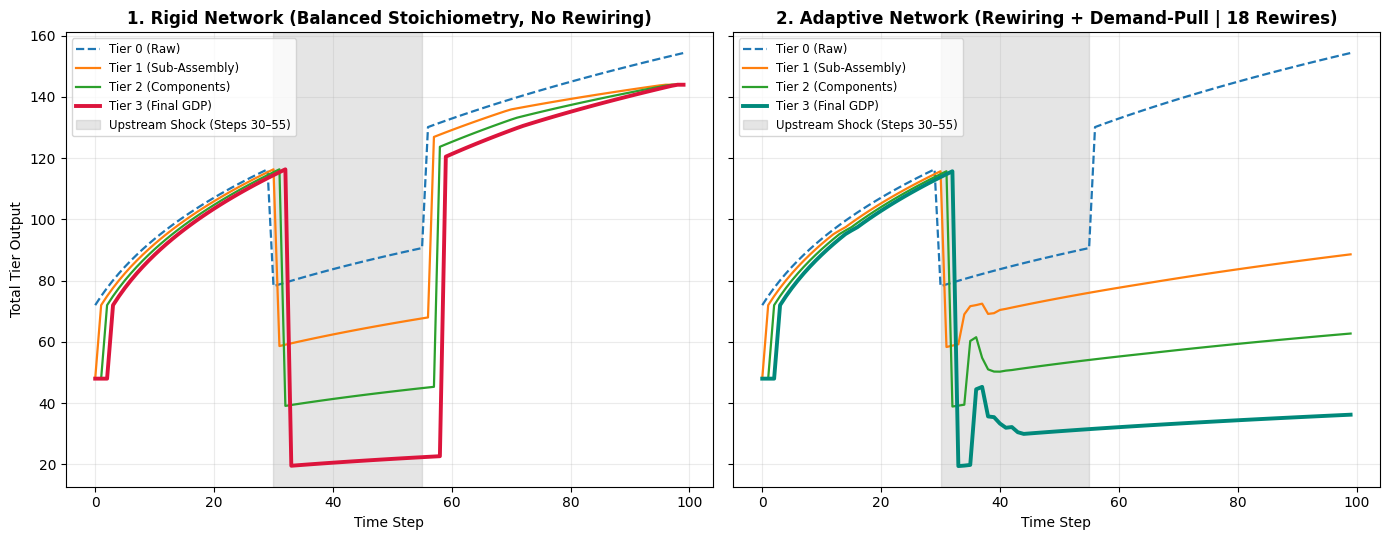

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)

# Plot 1: Rigid Supply Network
for col, lbl, style in [("Tier0_Output", "Tier 0 (Raw)", "--"),
                        ("Tier1_Output", "Tier 1 (Sub-Assembly)", "-"),
                        ("Tier2_Output", "Tier 2 (Components)", "-"),
                        ("Final_GDP", "Tier 3 (Final GDP)", "-")]:
    lw = 2.8 if col == "Final_GDP" else 1.6
    color = "crimson" if col == "Final_GDP" else None
    ax1.plot(df_rigid[col], label=lbl, linestyle=style, linewidth=lw, color=color)

ax1.axvspan(30, 55, color="gray", alpha=0.2, label="Upstream Shock (Steps 30–55)")
ax1.set_title("1. Rigid Network (Balanced Stoichiometry, No Rewiring)", fontweight="bold")
ax1.set_xlabel("Time Step")
ax1.set_ylabel("Total Tier Output")
ax1.legend(loc="upper left", fontsize=8.5)
ax1.grid(alpha=0.25)

for col, lbl, style in [("Tier0_Output", "Tier 0 (Raw)", "--"),
                        ("Tier1_Output", "Tier 1 (Sub-Assembly)", "-"),
                        ("Tier2_Output", "Tier 2 (Components)", "-"),
                        ("Final_GDP", "Tier 3 (Final GDP)", "-")]:
    lw = 2.8 if col == "Final_GDP" else 1.6
    color = "#00897B" if col == "Final_GDP" else None
    ax2.plot(df_adapt[col], label=lbl, linestyle=style, linewidth=lw, color=color)

ax2.axvspan(30, 55, color="gray", alpha=0.2, label="Upstream Shock (Steps 30–55)")
ax2.set_title(f"2. Adaptive Network (Rewiring + Demand-Pull | {adaptive_model.rewire_events} Rewires)", fontweight="bold")
ax2.set_xlabel("Time Step")
ax2.legend(loc="upper left", fontsize=8.5)
ax2.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [ ]:
'''

If we look closely in the right diagram
even after shock the Output of tier 1,2 and 3 doesnt go back to where it was
before the shock, this is due to the fact that after rewiring to
new suppliers the tiers donot want to go back to the old
suppliers, so even though the output of tier 0 is increasing, the
nodes that were disrupted do not have any downstream demand, so
their product is just unused.

Because when a starved node rewires to a healthy supplier,
that healthy supplier suddenly has to split its output among 3 or 4 customers instead of 2!
'''

In [ ]:
def plot_supply_dag(ax, model, title):
    G = model.G
    pos = {}

    for t_idx, tier_agents in enumerate(model.tiers):
        n_nodes = len(tier_agents)
        for row_idx, agent in enumerate(tier_agents):
            y_pos = (n_nodes - 1) / 2.0 - row_idx
            pos[agent.unique_id] = (t_idx, y_pos)

    node_ids = list(G.nodes())
    outputs = [model.agent_map[nid].current_output for nid in node_ids]
    out_degrees = [G.out_degree(nid) for nid in node_ids]

    node_sizes = [350 + 220 * deg for deg in out_degrees]

    nx.draw_networkx_edges(
        G, pos, ax=ax,
        edge_color="#546E7A", alpha=0.55,
        arrows=True, arrowsize=14,
        connectionstyle="arc3,rad=0.06",
        width=1.4
    )

    # Draw worker nodes colored by final step output
    nodes_draw = nx.draw_networkx_nodes(
        G, pos, nodelist=node_ids, ax=ax,
        node_size=node_sizes,
        node_color=outputs,
        cmap=plt.cm.viridis,
        vmin=0, vmax=28,
        edgecolors="black", linewidths=1.2
    )

    # Highlight the 2 formerly-disrupted Tier-0 nodes with a red ring
    nx.draw_networkx_nodes(
        G, pos, nodelist=model.target_nodes, ax=ax,
        node_size=[node_sizes[node_ids.index(nid)] + 180 for nid in model.target_nodes],
        node_color="none",
        edgecolors="crimson", linewidths=2.5
    )

    labels = {
        nid: f"#{nid}\nY:{model.agent_map[nid].current_output:.0f}\n(k_out:{G.out_degree(nid)})"
        for nid in node_ids
    }
    nx.draw_networkx_labels(G, pos, labels=labels, ax=ax, font_size=7.5, font_weight="bold", font_color="white")

    ax.set_title(title, fontweight="bold", fontsize=11)
    ax.set_xticks([0, 1, 2, 3])
    ax.set_xticklabels(["Tier 0\n(Raw)", "Tier 1\n(Sub-Assy)", "Tier 2\n(Comp)", "Tier 3\n(Final GDP)"], fontweight="bold")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.set_xlim(-0.5, 3.5)
    return nodes_draw


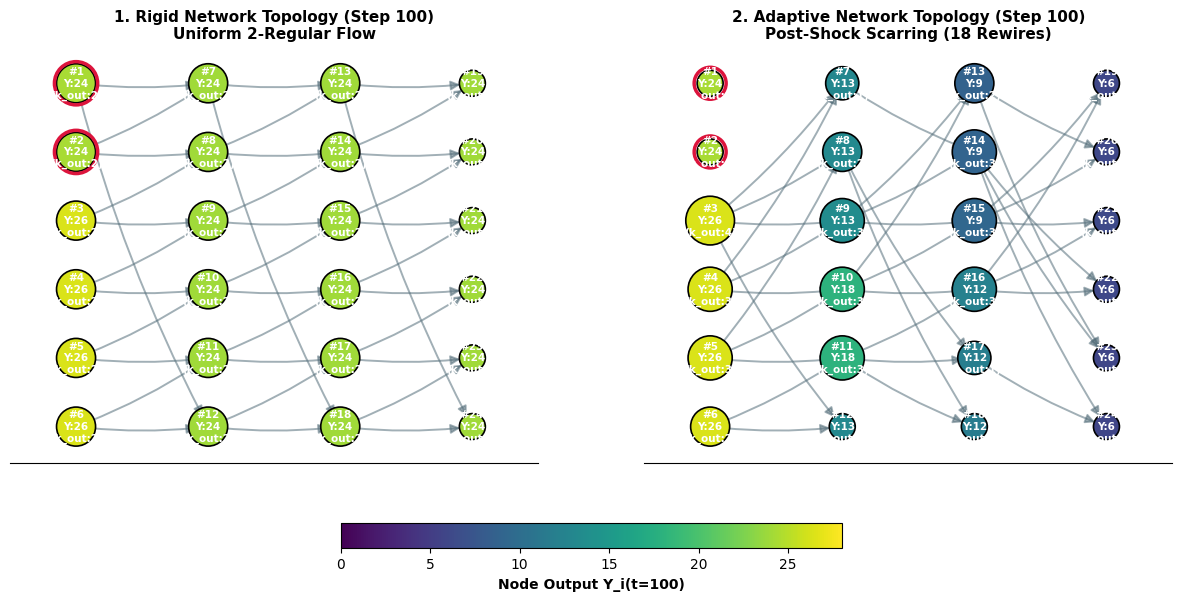

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.5))

n1 = plot_supply_dag(ax1, rigid_model, "1. Rigid Network Topology (Step 100)\nUniform 2-Regular Flow")
n2 = plot_supply_dag(ax2, adaptive_model, f"2. Adaptive Network Topology (Step 100)\nPost-Shock Scarring ({adaptive_model.rewire_events} Rewires)")

cbar = fig.colorbar(n2, ax=[ax1, ax2], orientation="horizontal", fraction=0.05, pad=0.12)
cbar.set_label("Node Output Y_i(t=100)", fontweight="bold")

plt.show()

In [ ]:
import itertools, numpy as np, pandas as pd, matplotlib.pyplot as plt

In [ ]:

NO_SHOCK = (10**9, 10**9)
PAIRS = list(itertools.combinations(range(6), 2))   # every choice of 2 shocked Tier-0 firms (15 scenarios)

def run(T=100, shocked=(0, 1), **kw):
  """Run SupplyNetworkModel2 for T steps; `shocked` = indices of the Tier-0 firms to knock out."""
  m = SupplyNetworkModel2(**kw)
  m.target_nodes = [m.tiers[0][i].unique_id for i in shocked]
  for _ in range(T):
    m.step()
  return m.datacollector.get_model_vars_dataframe()

_base_cache = {}
def baseline(T, **kw):
  """Same economy, no shock (the counterfactual). Cached: it doesn't depend on which firms get shocked."""
  key = (T, tuple(sorted(kw.items())))
  if key not in _base_cache:
    _base_cache[key] = run(T, shock_window=NO_SHOCK, **kw)["Final_GDP"].values
  return _base_cache[key]

def measure(T=100, shocked=(0, 1), tail=10, **kw):
  gdp = run(T, shocked=shocked, **kw)
  s, b = gdp["Final_GDP"].values, baseline(T, **{k: v for k, v in kw.items() if k != "shock_window"})
  return dict(perm_loss=1 - s[-tail:].mean() / b[-tail:].mean(),   # loss still there at the end
              cum_loss=1 - s.sum() / b.sum(),                       # total GDP lost over the run
              rewires=gdp["cumulative_Rewires"].iloc[-1], gdp=s, base=b)



In [ ]:
MODELS = {"rigid":    dict(enable_rewiring=False, enable_demand_pull=False),
          "adaptive": dict(enable_rewiring=True,  enable_demand_pull=True)}

In [ ]:
rows = []
for name, kw in MODELS.items():
  for pair in PAIRS:
    r = measure(shocked=pair, shock_window=(30, 55), **kw)
    rows.append(dict(model=name, shocked=pair, **{k: r[k] for k in ("perm_loss", "cum_loss", "rewires")}))

/usr/local/lib/python3.13/dist-packages/mesa/mesa_logging.py:112: FutureWarning: The use of the `seed` keyword argument is deprecated, use `rng` instead. No functional changes.
  res = func(*args, **kwargs)


In [ ]:
df1 = pd.DataFrame(rows)
print(df1.groupby("model")[["perm_loss", "cum_loss", "rewires"]].describe().T.round(3))

model            adaptive   rigid
perm_loss count    15.000  15.000
          mean      0.656   0.012
          std       0.085   0.001
          min       0.541   0.011
          25%       0.590   0.011
          50%       0.619   0.013
          75%       0.730   0.013
          max       0.820   0.013
cum_loss  count    15.000  15.000
          mean      0.506   0.285
          std       0.057   0.026
          min       0.428   0.255
          25%       0.462   0.255
          50%       0.482   0.306
          75%       0.555   0.306
          max       0.617   0.306
rewires   count    15.000  15.000
          mean     20.800   0.000
          std       2.484   0.000
          min      18.000   0.000
          25%      18.000   0.000
          50%      22.000   0.000
          75%      22.000   0.000
          max      24.000   0.000


In [ ]:
durations = [5, 10, 20, 30, 50, 80, 120]
rows = []
for name, kw in MODELS.items():
  for d in durations:
    for pair in PAIRS:
      r = measure(T=200, shocked=pair, shock_window=(30, 30 + d), **kw)
      rows.append(dict(model=name, duration=d, perm_loss=r["perm_loss"], cum_loss=r["cum_loss"]))
df2 = pd.DataFrame(rows)
print(df2.groupby(["model", "duration"])[["perm_loss", "cum_loss"]].median().unstack(0).round(3))

/usr/local/lib/python3.13/dist-packages/mesa/mesa_logging.py:112: FutureWarning: The use of the `seed` keyword argument is deprecated, use `rng` instead. No functional changes.
  res = func(*args, **kwargs)


         perm_loss        cum_loss       
model     adaptive  rigid adaptive  rigid
duration                                 
5             0.54  0.000    0.531  0.032
10            0.54  0.000    0.531  0.059
20            0.54  0.000    0.531  0.113
30            0.54  0.000    0.531  0.167
50            0.54  0.000    0.531  0.276
80            0.54  0.000    0.531  0.438
120           0.54  0.002    0.531  0.654


In [ ]:
patiences = [1, 2, 3, 5, 8, 12]
penalties = [0.0, 0.1, 0.25, 0.5]
heat = np.zeros((len(patiences), len(penalties)))
rew = np.zeros_like(heat)
for i, p in enumerate(patiences):
  for j, sp in enumerate(penalties):
    rs = [measure(shocked=pair, shock_window=(30, 55), patience_threshold=p, switching_penalty=sp,
                      **MODELS["adaptive"]) for pair in PAIRS]
    heat[i, j] = np.median([r["perm_loss"] for r in rs])
    rew[i, j] = np.median([r["rewires"] for r in rs])
print(pd.DataFrame(heat, index=[f"patience {p}" for p in patiences], columns=[f"penalty {s}" for s in penalties]).round(3))

/usr/local/lib/python3.13/dist-packages/mesa/mesa_logging.py:112: FutureWarning: The use of the `seed` keyword argument is deprecated, use `rng` instead. No functional changes.
  res = func(*args, **kwargs)


             penalty 0.0  penalty 0.1  penalty 0.25  penalty 0.5
patience 1         0.680        0.624         0.621        0.614
patience 2         0.680        0.624         0.620        0.613
patience 3         0.679        0.623         0.619        0.612
patience 5         0.678        0.621         0.617        0.610
patience 8         0.677        0.618         0.614        0.674
patience 12        0.674        0.614         0.611        0.672


/usr/local/lib/python3.13/dist-packages/mesa/mesa_logging.py:112: FutureWarning: The use of the `seed` keyword argument is deprecated, use `rng` instead. No functional changes.
  res = func(*args, **kwargs)


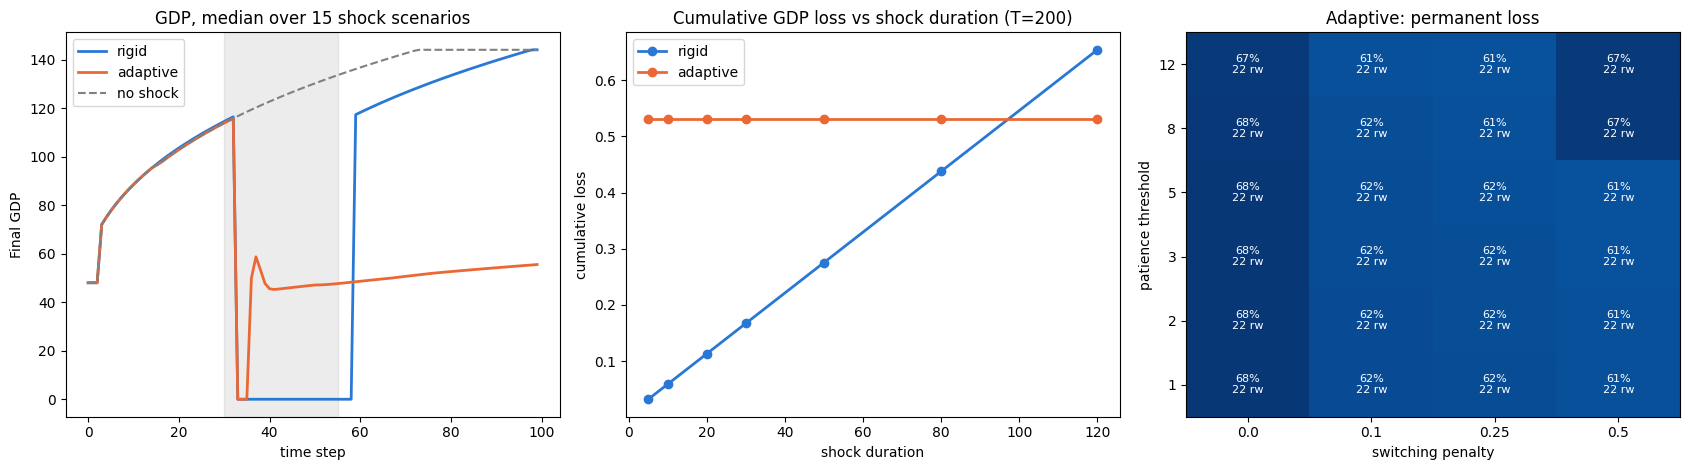

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))

# (a) median GDP path, 25-step shock
for name, col in [("rigid", "#2a78d6"), ("adaptive", "#eb6834")]:
  rs = [measure(shocked=pair, shock_window=(30, 55), **MODELS[name]) for pair in PAIRS]
  ax[0].plot(np.median([r["gdp"] for r in rs], 0), color=col, lw=2, label=name)
ax[0].plot(rs[0]["base"], color="gray", ls="--", label="no shock")
ax[0].axvspan(30, 55, color="gray", alpha=0.15)
ax[0].set(title="GDP, median over 15 shock scenarios", xlabel="time step", ylabel="Final GDP")
ax[0].legend()

# (b) cumulative loss vs shock duration
med = df2.groupby(["model", "duration"])["cum_loss"].median().unstack(0)
for name, col in [("rigid", "#2a78d6"), ("adaptive", "#eb6834")]:
  ax[1].plot(med.index, med[name], "o-", color=col, lw=2, label=name)
ax[1].set(title="Cumulative GDP loss vs shock duration (T=200)", xlabel="shock duration", ylabel="cumulative loss")
ax[1].legend()

# (c) permanent loss heatmap
im = ax[2].imshow(heat, cmap="Blues", vmin=0, vmax=max(0.7, heat.max()), aspect="auto", origin="lower")
ax[2].set_xticks(range(len(penalties))); ax[2].set_xticklabels(penalties)
ax[2].set_yticks(range(len(patiences))); ax[2].set_yticklabels(patiences)
for i in range(len(patiences)):
  for j in range(len(penalties)):
    ax[2].text(j, i, f"{heat[i,j]:.0%}\n{rew[i,j]:.0f} rw", ha="center", va="center", fontsize=8,
                   color="white" if heat[i, j] > 0.4 else "black")
ax[2].set(title="Adaptive: permanent loss", xlabel="switching penalty", ylabel="patience threshold")
plt.tight_layout(); plt.show()

In [ ]:
'''
Patience barely matters

We can improve this model further by adding the ability to rewire when sommeone is providing supply more worthy.
As in our model the rewiring happens when some of hte Tier 0 nodes are affected by shock. And they lose their customers forever. And the supply the downstream
nodes are getting becomes scarse, as a result their output productivity decreases. We can improve this if we add the ability of the nodes to rewire again with
those that were affected by shocks if they provide better deal.

Hence win-win situation.

We didnt implement this here but I feel its intuituve enough to make sense of it.

:)

What i wanna do next is instead of hard coding the algo, we will see
this behaviour emerge thorugh inteeraction of agents using RL

'''